In [1]:
import os

print(os.getcwd())

d:\AgriGuard


In [6]:
import sys
print(sys.executable)

import pandas
import numpy
import sklearn

print("Everything working!")

d:\AgriGuard\venv\Scripts\python.exe
Everything working!


In [7]:
import pandas as pd

df = pd.read_csv("dataset/Data.csv")

print(df.shape)

(31465, 18)


In [8]:
print("Columns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Columns:
['m49_code', 'country', 'region', 'cpc_code', 'commodity', 'year', 'loss_percentage', 'loss_percentage_original', 'loss_quantity', 'activity', 'food_supply_stage', 'treatment', 'cause_of_loss', 'sample_size', 'method_data_collection', 'reference', 'url', 'notes']

First 5 rows:


,m49_code,country,region,cpc_code,commodity,year,loss_percentage,loss_percentage_original,loss_quantity,activity,food_supply_stage,treatment,cause_of_loss,sample_size,method_data_collection,reference,url,notes
0,1,World,NaN,0111,Wheat,2022,1.0,1%,NaN,Processing,Processing,NaN,NaN,NaN,Survey,"Aintzane Esturo, (2022), Cereals Extraction Ra...",NaN,Derived product is wheat flour
1,1,World,NaN,0112,Maize (corn),2022,0.5,0.5%,NaN,Processing,Processing,NaN,NaN,NaN,Survey,"Aintzane Esturo, (2022), Cereals Extraction Ra...",NaN,Derived product is maize flour.
2,1,World,NaN,0112,Maize (corn),2022,2.0,2%,NaN,Processing,Processing,NaN,NaN,NaN,Survey,"Aintzane Esturo, (2022), Cereals Extraction Ra...",NaN,Derived product is Maize (corn) grits.
3,1,World,NaN,0112,Maize (corn),2022,2.0,2%,NaN,Processing,Processing,NaN,NaN,NaN,Survey,"Aintzane Esturo, (2022), Cereals Extraction Ra...",NaN,Derived product is Maize (corn) grits flaked.
4,1,World,NaN,0112,Maize (corn),2022,0.1,0.1%,NaN,Processing,Processing,NaN,NaN,NaN,Survey,"Aintzane Esturo, (2022), Cereals Extraction Ra...",NaN,Derived product is corn starch.


In [9]:
missing_values = df.isnull().sum()

print(missing_values)
print("\nMissing percentage:")
print((df.isnull().sum() / len(df) * 100).round(2))

m49_code                        0
country                         0
region                      29429
cpc_code                        0
commodity                       0
year                            0
loss_percentage                 0
loss_percentage_original        0
loss_quantity               26415
activity                     7370
food_supply_stage            3391
treatment                   29678
cause_of_loss               30367
sample_size                 29603
method_data_collection         36
reference                      73
url                          9342
notes                       29931
dtype: int64

Missing percentage:
m49_code                     0.00
country                      0.00
region                      93.53
cpc_code                     0.00
commodity                    0.00
year                         0.00
loss_percentage              0.00
loss_percentage_original     0.00
loss_quantity               83.95
activity                    23.42
food_supply_st

In [10]:
print("Duplicate rows:", df.duplicated().sum())
print("\nDataset data types:")
print(df.dtypes)

Duplicate rows: 180

Dataset data types:
m49_code                      int64
country                         str
region                          str
cpc_code                        str
commodity                       str
year                          int64
loss_percentage             float64
loss_percentage_original        str
loss_quantity                   str
activity                        str
food_supply_stage               str
treatment                       str
cause_of_loss                   str
sample_size                     str
method_data_collection          str
reference                       str
url                             str
notes                           str
dtype: object


In [11]:
df_clean = df.drop_duplicates().copy()

print("Original rows:", len(df))
print("Rows after removing duplicates:", len(df_clean))
print("Duplicates removed:", len(df) - len(df_clean))

Original rows: 31465
Rows after removing duplicates: 31285
Duplicates removed: 180


In [12]:
print(df_clean["loss_percentage"].describe())
print("Minimum loss:", df_clean["loss_percentage"].min())
print("Maximum loss:", df_clean["loss_percentage"].max())
print("Average loss:", df_clean["loss_percentage"].mean())

count    31285.000000
mean         4.661938
std          6.360730
min          0.000000
25%          1.481480
50%          2.650000
75%          4.550000
max         65.000000
Name: loss_percentage, dtype: float64
Minimum loss: 0.0
Maximum loss: 65.0
Average loss: 4.661937577215502


Matplotlib is building the font cache; this may take a moment.


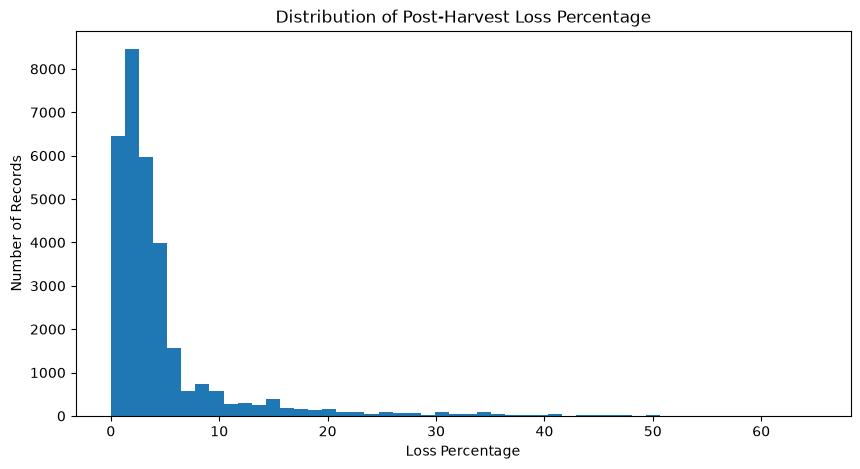

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(df_clean["loss_percentage"], bins=50)

plt.xlabel("Loss Percentage")
plt.ylabel("Number of Records")
plt.title("Distribution of Post-Harvest Loss Percentage")

plt.show()

In [14]:
print("Unique countries:", df_clean["country"].nunique())
print("Unique commodities:", df_clean["commodity"].nunique())
print("Unique activities:", df_clean["activity"].nunique())
print("Unique food supply stages:", df_clean["food_supply_stage"].nunique())
print("Unique years:", df_clean["year"].nunique())
print("\nFood Supply Stages:")
print(df_clean["food_supply_stage"].value_counts())

print("\nTop 15 Commodities:")
print(df_clean["commodity"].value_counts().head(15))

print("\nTop 15 Countries:")
print(df_clean["country"].value_counts().head(15))

Unique countries: 159
Unique commodities: 213
Unique activities: 180
Unique food supply stages: 20
Unique years: 27

Food Supply Stages:
food_supply_stage
Farm                  10095
Whole supply chain     6005
Harvest                4156
Storage                3212
Transport              2090
Retail                  747
Processing              437
Wholesale               319
Households              247
Post-harvest            168
Trader                  104
Market                  101
Export                   50
Packing                  48
Distribution             39
Pre-harvest              24
Food Services            23
Collector                16
Grading                  12
Stacking                  1
Name: count, dtype: int64

Top 15 Commodities:
commodity
Maize (corn)                       6088
Rice                               4876
Millet                             3684
Sorghum                            3531
Wheat                              2376
Fonio                       

In [15]:
print(df_clean["commodity"].value_counts().head(20))
print(df_clean["country"].value_counts().head(20))
print(df_clean["activity"].value_counts().head(20))

commodity
Maize (corn)                       6088
Rice                               4876
Millet                             3684
Sorghum                            3531
Wheat                              2376
Fonio                               968
Barley                              869
Potatoes                            655
Tomatoes                            482
Mangoes, guavas and mangosteens     289
Grapes                              256
Cabbages                            237
Oats                                220
Hen eggs in shell, fresh            208
Bananas                             186
Beans, dry                          184
Cauliflowers and broccoli           167
Apples                              164
Rye                                 156
Carrots and turnips                 144
Name: count, dtype: int64
country
United States of America       1575
India                          1428
Ethiopia                       1150
Kenya                          1050
Ghana       

In [16]:
commodity_loss = (
    df_clean.groupby("commodity")["loss_percentage"]
    .agg(["count", "mean"])
    .sort_values("count", ascending=False)
)

print(commodity_loss.head(20))

                                 count       mean
commodity                                        
Maize (corn)                      6088   3.994706
Rice                              4876   3.024269
Millet                            3684   2.156336
Sorghum                           3531   3.038945
Wheat                             2376   3.595920
Fonio                              968   2.523314
Barley                             869   2.875876
Potatoes                           655   8.040598
Tomatoes                           482  12.803815
Mangoes, guavas and mangosteens    289   9.419806
Grapes                             256   7.043906
Cabbages                           237  11.478502
Oats                               220   2.252273
Hen eggs in shell, fresh           208   2.321490
Bananas                            186  10.975806
Beans, dry                         184   6.178071
Cauliflowers and broccoli          167  10.881257
Apples                             164  10.413049


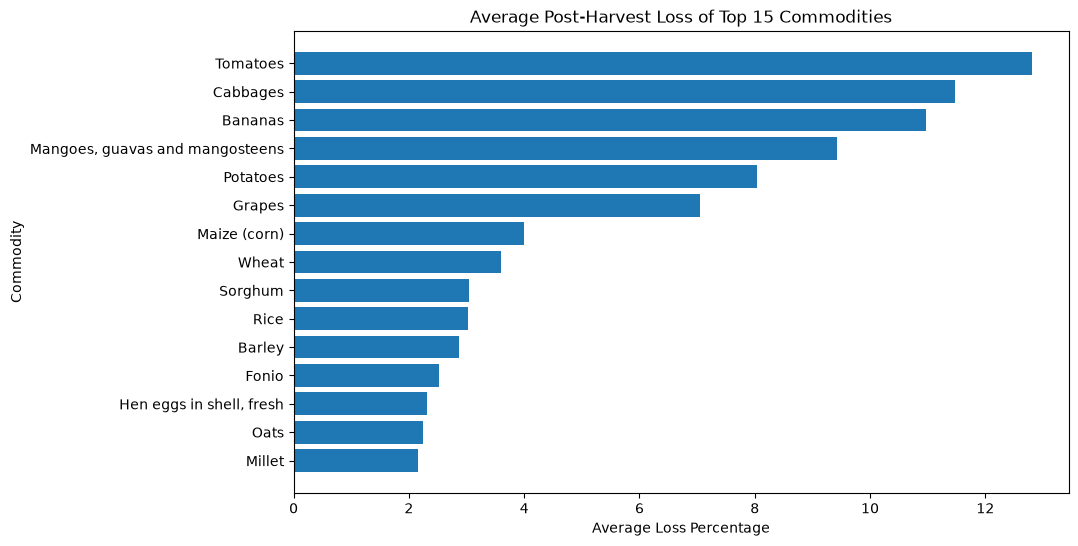

In [17]:
top_15 = commodity_loss.head(15).sort_values("mean", ascending=True)

plt.figure(figsize=(10, 6))

plt.barh(top_15.index, top_15["mean"])

plt.xlabel("Average Loss Percentage")
plt.ylabel("Commodity")
plt.title("Average Post-Harvest Loss of Top 15 Commodities")

plt.show()

In [18]:
year_loss = (
    df_clean.groupby("year")["loss_percentage"]
    .agg(["count", "mean"])
    .sort_index()
)

print(year_loss)

      count      mean
year                 
2000   1266  4.242073
2001   1418  4.585499
2002   1342  4.636016
2003   1289  4.663945
2004   1222  4.106772
2005   1304  5.058277
2006   1703  3.985249
2007   1293  4.142623
2008   1392  5.259207
2009   1713  4.789508
2010   1506  5.839726
2011   1380  4.769259
2012   1261  4.822995
2013   1492  6.178918
2014   1896  4.024757
2015   1615  4.955806
2016   1634  4.448499
2017   1466  5.048570
2018   1432  4.949585
2019   1179  4.094849
2020    953  3.594414
2021   1053  3.070686
2022    231  5.207835
2023     80  9.782438
2024    155  5.641290
2025      5  4.200000
2026      5  4.508000


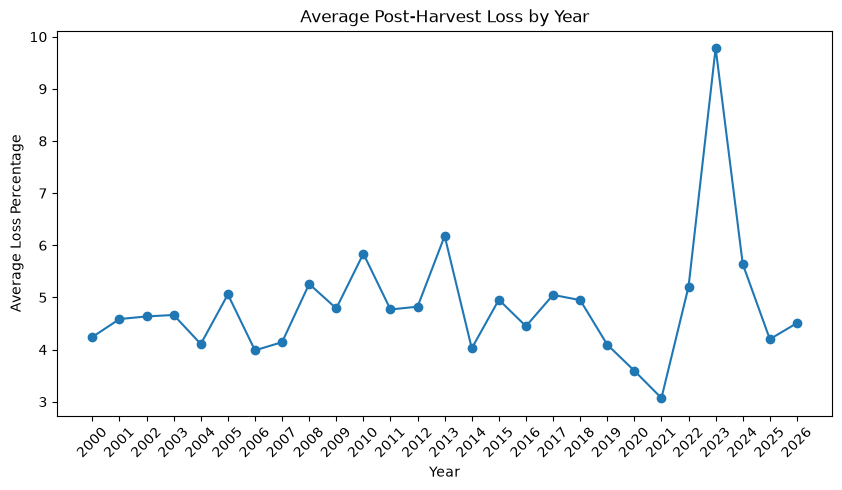

In [19]:
plt.figure(figsize=(10, 5))

plt.plot(year_loss.index, year_loss["mean"], marker="o")

plt.xlabel("Year")
plt.ylabel("Average Loss Percentage")
plt.title("Average Post-Harvest Loss by Year")

plt.xticks(year_loss.index, rotation=45)

plt.show()

In [20]:
stage_loss = (
    df_clean.groupby("food_supply_stage")["loss_percentage"]
    .agg(["count", "mean"])
    .sort_values("count", ascending=False)
)

print(stage_loss)

                    count       mean
food_supply_stage                   
Farm                10095   2.896696
Whole supply chain   6005   7.631121
Harvest              4156   5.023940
Storage              3212   3.938508
Transport            2090   1.838746
Retail                747  12.335074
Processing            437   5.550800
Wholesale             319   8.331987
Households            247  15.382227
Post-harvest          168  17.183601
Trader                104   6.620918
Market                101   4.135644
Export                 50  10.877800
Packing                48   4.703125
Distribution           39   5.704103
Pre-harvest            24   7.450833
Food Services          23   9.333043
Collector              16   9.959687
Grading                12   7.791667
Stacking                1   2.100000


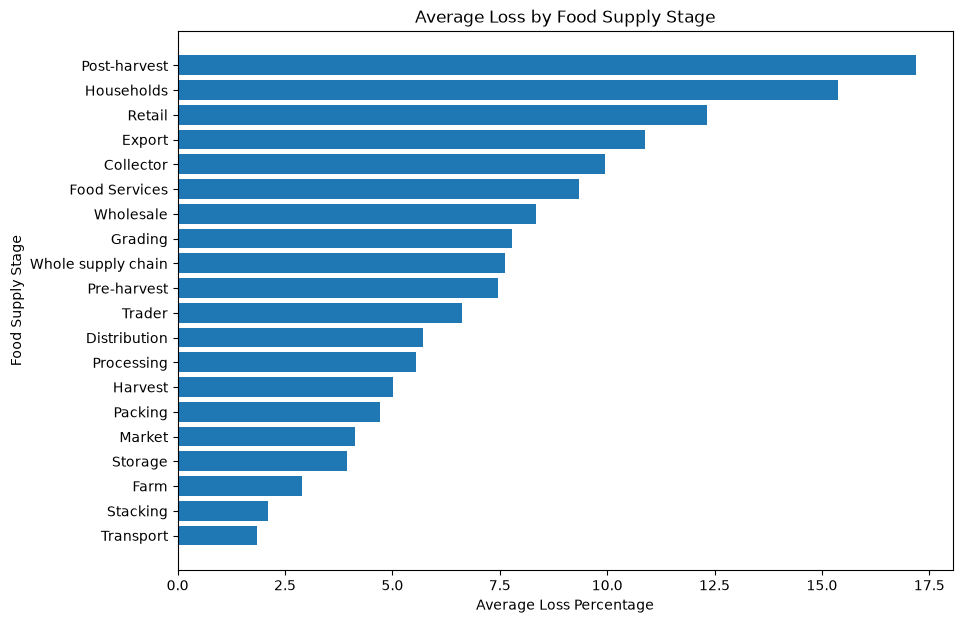

In [21]:
stage_plot = stage_loss.sort_values("mean", ascending=True)

plt.figure(figsize=(10, 7))

plt.barh(stage_plot.index, stage_plot["mean"])

plt.xlabel("Average Loss Percentage")
plt.ylabel("Food Supply Stage")
plt.title("Average Loss by Food Supply Stage")

plt.show()

In [22]:
missing_summary = (
    df_clean.isnull()
    .sum()
    .to_frame("missing_count")
)

missing_summary["missing_percentage"] = (
    missing_summary["missing_count"] / len(df_clean) * 100
)

missing_summary = missing_summary.sort_values(
    "missing_percentage",
    ascending=False
)

print(missing_summary)

                          missing_count  missing_percentage
cause_of_loss                     30195           96.515902
notes                             29752           95.099888
treatment                         29502           94.300783
sample_size                       29442           94.108998
region                            29251           93.498482
loss_quantity                     26235           83.858079
url                                9324           29.803420
activity                           7206           23.033403
food_supply_stage                  3391           10.839060
reference                            73            0.233339
method_data_collection               36            0.115071
m49_code                              0            0.000000
country                               0            0.000000
loss_percentage                       0            0.000000
cpc_code                              0            0.000000
loss_percentage_original              0 

In [23]:
print("Activity missing rows:")
print(df_clean[df_clean["activity"].isna()][
    ["commodity", "year", "loss_percentage"]
].head(10))

print("\nFood supply stage missing rows:")
print(df_clean[df_clean["food_supply_stage"].isna()][
    ["commodity", "year", "loss_percentage"]
].head(10))
print("Activity missing:", df_clean["activity"].isna().sum())
print("Food supply stage missing:", df_clean["food_supply_stage"].isna().sum())

Activity missing rows:
                         commodity  year  loss_percentage
27                     Mixed grain  2018             9.99
35   Groundnuts, excluding shelled  2009             5.22
36   Groundnuts, excluding shelled  2008             5.43
37   Groundnuts, excluding shelled  2007             5.61
38   Groundnuts, excluding shelled  2006             5.40
39   Groundnuts, excluding shelled  2005             5.00
40   Groundnuts, excluding shelled  2004             5.00
41   Groundnuts, excluding shelled  2003             5.00
111                          Wheat  2019            14.50
112                   Maize (corn)  2019            18.00

Food supply stage missing rows:
       commodity  year  loss_percentage
44         Wheat  2021          3.50000
47  Maize (corn)  2021          1.32000
53          Rice  2021          3.13714
58       Sorghum  2021          3.60000
62        Millet  2021          2.00000
67         Wheat  2020          3.50000
70  Maize (corn)  2020    

In [24]:
ml_df = df_clean[
    [
        "country",
        "commodity",
        "year",
        "activity",
        "food_supply_stage",
        "loss_percentage"
    ]
].copy()

ml_df["activity"] = ml_df["activity"].fillna("Unknown")
ml_df["food_supply_stage"] = ml_df["food_supply_stage"].fillna("Unknown")

print(ml_df.shape)
print(ml_df.isnull().sum())

(31285, 6)
country              0
commodity            0
year                 0
activity             0
food_supply_stage    0
loss_percentage      0
dtype: int64


In [25]:
X = ml_df[
    [
        "country",
        "commodity",
        "year",
        "activity",
        "food_supply_stage"
    ]
]

y = ml_df["loss_percentage"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nFeatures:")
print(X.columns.tolist())
print("\nTarget:")
print(y.name)

X shape: (31285, 5)
y shape: (31285,)

Features:
['country', 'commodity', 'year', 'activity', 'food_supply_stage']

Target:
loss_percentage


In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (25028, 5)
X_test: (6257, 5)
y_train: (25028,)
y_test: (6257,)


In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = [
    "country",
    "commodity",
    "activity",
    "food_supply_stage"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="passthrough"
)

X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print("X_train encoded shape:", X_train_encoded.shape)
print("X_test encoded shape:", X_test_encoded.shape)

X_train encoded shape: (25028, 556)
X_test encoded shape: (6257, 556)


In [28]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train_encoded, y_train)

print("Model training completed!")

Model training completed!


In [29]:
y_pred = model.predict(X_test_encoded)

print("First 10 actual values:")
print(y_test.head(10).values)

print("\nFirst 10 predicted values:")
print(y_pred[:10])

First 10 actual values:
[ 2.16667 25.       1.       3.5     10.7854   3.42     1.86     2.65
  4.7      2.     ]

First 10 predicted values:
[2.16667    3.18493333 1.         3.5        4.7949294  3.39
 1.93298814 2.65       6.96498333 2.        ]


In [30]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R² Score:", r2)

MAE: 1.1936239869602356
RMSE: 3.847283186899389
R² Score: 0.6658799346444058


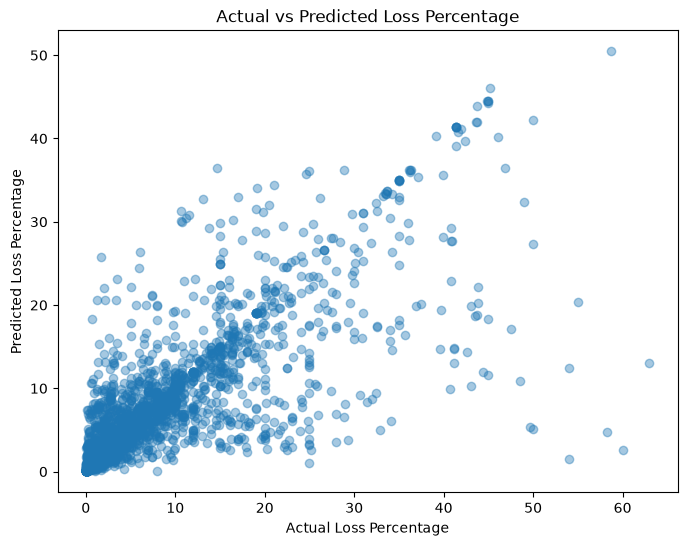

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.4)

plt.xlabel("Actual Loss Percentage")
plt.ylabel("Predicted Loss Percentage")
plt.title("Actual vs Predicted Loss Percentage")

plt.show()

In [32]:
import pandas as pd

feature_names = preprocessor.get_feature_names_out()

importance = pd.Series(
    model.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

print(importance.head(15))

remainder__year                                      0.087267
categorical__country_United States of America        0.077975
categorical__activity_Unknown                        0.070220
categorical__food_supply_stage_Whole supply chain    0.056621
categorical__country_Peru                            0.049674
categorical__commodity_Grapefruit juice              0.019810
categorical__commodity_Tomatoes                      0.019458
categorical__commodity_Orange juice                  0.019256
categorical__commodity_Pineapple juice               0.016424
categorical__food_supply_stage_Retail                0.013773
categorical__commodity_Canned mushrooms              0.012903
categorical__country_Ethiopia                        0.012837
categorical__food_supply_stage_Harvest               0.012513
categorical__commodity_Maize (corn)                  0.012119
categorical__commodity_Papayas                       0.011438
dtype: float64


In [33]:
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

results["Absolute_Error"] = (
    results["Actual"] - results["Predicted"]
).abs()

print("Average error:", results["Absolute_Error"].mean())

print("\nLargest 10 errors:")
print(
    results.sort_values(
        "Absolute_Error",
        ascending=False
    ).head(10)
)

Average error: 1.1936239869602356

Largest 10 errors:
      Actual  Predicted  Absolute_Error
3739   60.00   2.650000       57.350000
1801   58.30   4.811467       53.488533
3631   54.05   1.477039       52.572961
1716   63.00  13.036483       49.963517
611    50.00   5.093942       44.906058
6246   49.70   5.317155       44.382845
6037   54.00  12.453845       41.546155
1702   48.50  10.935268       37.564732
2559   55.00  20.384417       34.615583
5412   45.00  11.657500       33.342500


In [34]:
print("Test records with loss >= 20%:", (y_test >= 20).sum())
print("Test records with loss >= 30%:", (y_test >= 30).sum())
print("Test records with loss >= 40%:", (y_test >= 40).sum())
print("Test records with loss >= 50%:", (y_test >= 50).sum())

Test records with loss >= 20%: 262
Test records with loss >= 30%: 114
Test records with loss >= 40%: 51
Test records with loss >= 50%: 10


In [35]:
import joblib

joblib.dump(model, "agriguard_model.pkl")
joblib.dump(preprocessor, "agriguard_preprocessor.pkl")

print("Model and preprocessor saved successfully!")

Model and preprocessor saved successfully!


In [36]:
print("Minimum year:", ml_df["year"].min())
print("Maximum year:", ml_df["year"].max())
print("\nYear distribution:")
print(ml_df["year"].value_counts().sort_index())

Minimum year: 2000
Maximum year: 2026

Year distribution:
year
2000    1266
2001    1418
2002    1342
2003    1289
2004    1222
2005    1304
2006    1703
2007    1293
2008    1392
2009    1713
2010    1506
2011    1380
2012    1261
2013    1492
2014    1896
2015    1615
2016    1634
2017    1466
2018    1432
2019    1179
2020     953
2021    1053
2022     231
2023      80
2024     155
2025       5
2026       5
Name: count, dtype: int64


In [37]:
train_df = ml_df[ml_df["year"] <= 2022].copy()
test_df = ml_df[
    (ml_df["year"] >= 2023) &
    (ml_df["year"] <= 2024)
].copy()

print("Training data:", train_df.shape)
print("Testing data:", test_df.shape)

print("\nTraining years:")
print(train_df["year"].min(), "to", train_df["year"].max())

print("\nTesting years:")
print(test_df["year"].min(), "to", test_df["year"].max())

Training data: (31040, 6)
Testing data: (235, 6)

Training years:
2000 to 2022

Testing years:
2023 to 2024


In [38]:
X_train_time = train_df[
    [
        "country",
        "commodity",
        "year",
        "activity",
        "food_supply_stage"
    ]
]

y_train_time = train_df["loss_percentage"]

X_test_time = test_df[
    [
        "country",
        "commodity",
        "year",
        "activity",
        "food_supply_stage"
    ]
]

y_test_time = test_df["loss_percentage"]

print("X_train:", X_train_time.shape)
print("X_test:", X_test_time.shape)
print("y_train:", y_train_time.shape)
print("y_test:", y_test_time.shape)

X_train: (31040, 5)
X_test: (235, 5)
y_train: (31040,)
y_test: (235,)


In [39]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = [
    "country",
    "commodity",
    "activity",
    "food_supply_stage"
]

time_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="passthrough"
)

X_train_time_encoded = time_preprocessor.fit_transform(X_train_time)
X_test_time_encoded = time_preprocessor.transform(X_test_time)

print("X_train encoded:", X_train_time_encoded.shape)
print("X_test encoded:", X_test_time_encoded.shape)

X_train encoded: (31040, 571)
X_test encoded: (235, 571)


In [40]:
from sklearn.ensemble import RandomForestRegressor

time_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

time_model.fit(X_train_time_encoded, y_train_time)

print("Time-based model training completed!")

Time-based model training completed!


In [41]:
y_pred_time = time_model.predict(X_test_time_encoded)

print("First 10 actual values:")
print(y_test_time.head(10).values)

print("\nFirst 10 predicted values:")
print(y_pred_time[:10])

First 10 actual values:
[20.43 19.62 15.93 22.46 26.54 19.58 14.46 25.74  1.75  0.81]

First 10 predicted values:
[16.98350429 16.98350429  8.86666786 16.98350429 18.427565   16.98350429
 16.973165   16.98350429  1.72864426  1.26163932]


In [42]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae_time = mean_absolute_error(y_test_time, y_pred_time)
rmse_time = mean_squared_error(y_test_time, y_pred_time) ** 0.5
r2_time = r2_score(y_test_time, y_pred_time)

print("Time-based MAE:", mae_time)
print("Time-based RMSE:", rmse_time)
print("Time-based R²:", r2_time)

Time-based MAE: 4.851355972566805
Time-based RMSE: 7.665882501690424
Time-based R²: 0.24125065028873927


In [43]:
baseline_prediction = y_train_time.mean()

baseline_pred = [baseline_prediction] * len(y_test_time)

baseline_mae = mean_absolute_error(y_test_time, baseline_pred)
baseline_rmse = mean_squared_error(y_test_time, baseline_pred) ** 0.5
baseline_r2 = r2_score(y_test_time, baseline_pred)

print("Baseline average loss:", baseline_prediction)
print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)
print("Baseline R²:", baseline_r2)

Baseline average loss: 4.6439491656954575
Baseline MAE: 5.36124096797352
Baseline RMSE: 9.123864985654052
Baseline R²: -0.074810041357944


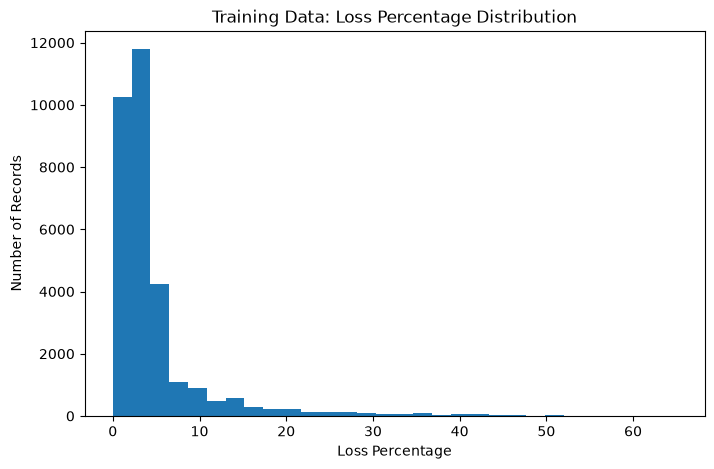

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    y_train_time,
    bins=30
)

plt.xlabel("Loss Percentage")
plt.ylabel("Number of Records")
plt.title("Training Data: Loss Percentage Distribution")

plt.show()

In [45]:
import numpy as np

y_train_log = np.log1p(y_train_time)

print("Original target:")
print(y_train_time.head())

print("\nTransformed target:")
print(y_train_log.head())

Original target:
0    1.0
1    0.5
2    2.0
3    2.0
4    0.1
Name: loss_percentage, dtype: float64

Transformed target:
0    0.693147
1    0.405465
2    1.098612
3    1.098612
4    0.095310
Name: loss_percentage, dtype: float64


In [46]:
log_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

log_model.fit(
    X_train_time_encoded,
    y_train_log
)

print("Log-transformed model training completed!")

Log-transformed model training completed!


In [47]:
y_pred_log = log_model.predict(X_test_time_encoded)

# Convert predictions back to original loss percentage scale
y_pred_log_original = np.expm1(y_pred_log)

print("First 10 actual values:")
print(y_test_time.head(10).values)

print("\nFirst 10 predicted values:")
print(y_pred_log_original[:10])

First 10 actual values:
[20.43 19.62 15.93 22.46 26.54 19.58 14.46 25.74  1.75  0.81]

First 10 predicted values:
[16.75062731 16.12979163  9.37197078 15.81626009 19.40718571 15.84039247
 12.77629857 15.66078359  1.85519814  2.65663013]


In [48]:
mae_log = mean_absolute_error(y_test_time, y_pred_log_original)
rmse_log = mean_squared_error(y_test_time, y_pred_log_original) ** 0.5
r2_log = r2_score(y_test_time, y_pred_log_original)

print("Log-transformed MAE:", mae_log)
print("Log-transformed RMSE:", rmse_log)
print("Log-transformed R²:", r2_log)

Log-transformed MAE: 4.622856027667335
Log-transformed RMSE: 7.775647935783294
Log-transformed R²: 0.21936648651370294


In [49]:
from sklearn.ensemble import HistGradientBoostingRegressor

boost_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=31,
    random_state=42
)

boost_model.fit(
    X_train_time_encoded.toarray(),
    y_train_time
)

print("Gradient Boosting model training completed!")

Gradient Boosting model training completed!


In [50]:
y_pred_boost = boost_model.predict(
    X_test_time_encoded.toarray()
)

print("First 10 actual values:")
print(y_test_time.head(10).values)

print("\nFirst 10 predicted values:")
print(y_pred_boost[:10])

First 10 actual values:
[20.43 19.62 15.93 22.46 26.54 19.58 14.46 25.74  1.75  0.81]

First 10 predicted values:
[19.56712377 15.09762782 16.79391077 17.11410979 18.61059754 16.17209599
 16.49031491 15.24179501  2.02549196  1.41294954]


In [51]:
mae_boost = mean_absolute_error(y_test_time, y_pred_boost)
rmse_boost = mean_squared_error(y_test_time, y_pred_boost) ** 0.5
r2_boost = r2_score(y_test_time, y_pred_boost)

print("Gradient Boosting MAE:", mae_boost)
print("Gradient Boosting RMSE:", rmse_boost)
print("Gradient Boosting R²:", r2_boost)

Gradient Boosting MAE: 4.62672732497617
Gradient Boosting RMSE: 7.331241251055065
Gradient Boosting R²: 0.3060486299196682


In [52]:
error_df = pd.DataFrame({
    "Actual": y_test_time.values,
    "Predicted": y_pred_boost
})

error_df["Absolute_Error"] = (
    error_df["Actual"] - error_df["Predicted"]
).abs()

print("Worst 10 predictions:")
print(
    error_df
    .sort_values("Absolute_Error", ascending=False)
    .head(10)
)

Worst 10 predictions:
     Actual  Predicted  Absolute_Error
44    45.00   9.477210       35.522790
100   33.60   4.458304       29.141696
54    47.00  19.469438       27.530562
155   28.20   1.172272       27.027728
94    31.00   4.458304       26.541696
169   25.70  -0.313498       26.013498
231   45.00  19.895560       25.104440
51    32.65  13.245996       19.404004
96    23.20   4.458304       18.741696
53    38.00  19.469438       18.530562


In [53]:
print("Test set size:", len(y_test_time))

print("Loss >= 10%:", (y_test_time >= 10).sum())
print("Loss >= 20%:", (y_test_time >= 20).sum())
print("Loss >= 30%:", (y_test_time >= 30).sum())
print("Loss >= 40%:", (y_test_time >= 40).sum())

Test set size: 235
Loss >= 10%: 46
Loss >= 20%: 22
Loss >= 30%: 8
Loss >= 40%: 4


In [54]:
high_loss_test = error_df[error_df["Actual"] >= 10].copy()

print("High-loss test records:", len(high_loss_test))
print()
print(high_loss_test.sort_values("Actual", ascending=False).to_string(index=False))

High-loss test records: 46

 Actual  Predicted  Absolute_Error
  47.00  19.469438       27.530562
  45.00   9.477210       35.522790
  45.00  19.895560       25.104440
  43.80  26.004900       17.795100
  38.00  19.469438       18.530562
  33.60   4.458304       29.141696
  32.65  13.245996       19.404004
  31.00   4.458304       26.541696
  29.50  19.469438       10.030562
  28.20   1.172272       27.027728
  27.50  13.245996       14.254004
  26.54  18.610598        7.929402
  25.74  15.241795       10.498205
  25.70  -0.313498       26.013498
  25.40  15.184663       10.215337
  24.10  13.245996       10.854004
  23.20   4.458304       18.741696
  22.50  19.469438        3.030562
  22.46  17.114110        5.345890
  21.00  19.895560        1.104440
  20.43  19.567124        0.862876
  20.12  16.368707        3.751293
  19.62  15.097628        4.522372
  19.58  16.172096        3.407904
  18.40  10.788464        7.611536
  17.50   9.477210        8.022790
  17.30   9.202808        8

In [55]:
import joblib

joblib.dump(boost_model, "agriguard_boost_model.pkl")
joblib.dump(time_preprocessor, "agriguard_preprocessor.pkl")

print("Gradient Boosting model and preprocessor saved successfully!")

Gradient Boosting model and preprocessor saved successfully!
